In [35]:
import os, re, sys, copy, subprocess, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score)

try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42

def set_seed(seed=SEED):
    np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device :", device)

PyTorch 2.11.0+cpu | device : cpu


## 0. Chargement des données

In [36]:
FILE = "predictive_maintenance.csv"
SLUG = "machine-predictive-maintenance-classification"
CANDIDATES = [f"/kaggle/input/{SLUG}/{FILE}", f"/content/{FILE}", f"data/{FILE}", FILE]
path = next((p for p in CANDIDATES if os.path.exists(p)), None)

if path is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub
    path = os.path.join(kagglehub.dataset_download(f"shivamb/{SLUG}"), FILE)

raw = pd.read_csv(path)
raw.columns = [re.sub(r"[ \[\]]+", "_", c).strip("_") for c in raw.columns]
raw.head()

,UDI,Product_ID,Type,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Target,Failure_Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


## 1. Prétraitement : nettoyage et encodage

In [37]:
print("Dimensions :", raw.shape)
print("\nValeurs manquantes :\n", raw.isna().sum().to_string())
print("\nLignes dupliquées :", raw.duplicated().sum(), "| Product_ID dupliqués :", raw["Product_ID"].duplicated().sum())
print("\nFailure_Type :\n", raw["Failure_Type"].value_counts().to_string())
print("\nTarget (binaire) :\n", raw["Target"].value_counts().to_string())

# Cohérence entre la cible binaire (Target) et le type de panne (Failure_Type)
inc_a = (raw["Target"] == 1) & (raw["Failure_Type"] == "No Failure")
inc_b = (raw["Target"] == 0) & (raw["Failure_Type"] != "No Failure")
print(f"\nIncohérences : Target=1 mais 'No Failure' = {inc_a.sum()} | Target=0 mais panne déclarée = {inc_b.sum()}")
display(raw.loc[inc_a | inc_b, "Failure_Type"].value_counts())

Dimensions : (10000, 10)

Valeurs manquantes :
 UDI                      0
Product_ID               0
Type                     0
Air_temperature_K        0
Process_temperature_K    0
Rotational_speed_rpm     0
Torque_Nm                0
Tool_wear_min            0
Target                   0
Failure_Type             0

Lignes dupliquées : 0 | Product_ID dupliqués : 0

Failure_Type :
 Failure_Type
No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18

Target (binaire) :
 Target
0    9661
1     339

Incohérences : Target=1 mais 'No Failure' = 9 | Target=0 mais panne déclarée = 18


,count
Failure_Type,
Random Failures,18
No Failure,9


In [38]:

df = raw.loc[~(inc_a | inc_b)].drop(columns=["UDI", "Product_ID"]).reset_index(drop=True)
df["Type_enc"] = df["Type"].map({"L": 0, "M": 1, "H": 2})
df["temp_diff"] = df["Process_temperature_K"] - df["Air_temperature_K"]
df["power_W"] = df["Torque_Nm"] * df["Rotational_speed_rpm"] * 2 * np.pi / 60
df["wear_x_torque"] = df["Tool_wear_min"] * df["Torque_Nm"]

FEATURES = ["Type_enc", "Air_temperature_K", "Process_temperature_K", "Rotational_speed_rpm", "Torque_Nm",
            "Tool_wear_min", "temp_diff", "power_W", "wear_x_torque"]
le = LabelEncoder().fit(df["Failure_Type"]); y = le.transform(df["Failure_Type"]); CLASSES = list(le.classes_)
n_classes = len(CLASSES)
print("Lignes conservées :", len(df), "| classes :", dict(zip(range(n_classes), CLASSES)))

num = ["Air_temperature_K", "Process_temperature_K", "Rotational_speed_rpm", "Torque_Nm", "Tool_wear_min"]
q1, q3 = df[num].quantile(.25), df[num].quantile(.75); iqr = q3 - q1
out = ((df[num] < q1 - 1.5 * iqr) | (df[num] > q3 + 1.5 * iqr)).sum()
print("\nOutliers IQR par variable :\n", out.to_string())

Lignes conservées : 9973 | classes : {0: 'Heat Dissipation Failure', 1: 'No Failure', 2: 'Overstrain Failure', 3: 'Power Failure', 4: 'Tool Wear Failure'}

Outliers IQR par variable :
 Air_temperature_K          0
Process_temperature_K      0
Rotational_speed_rpm     418
Torque_Nm                 70
Tool_wear_min              0


## 2. Analyse exploratoire des données (EDA)

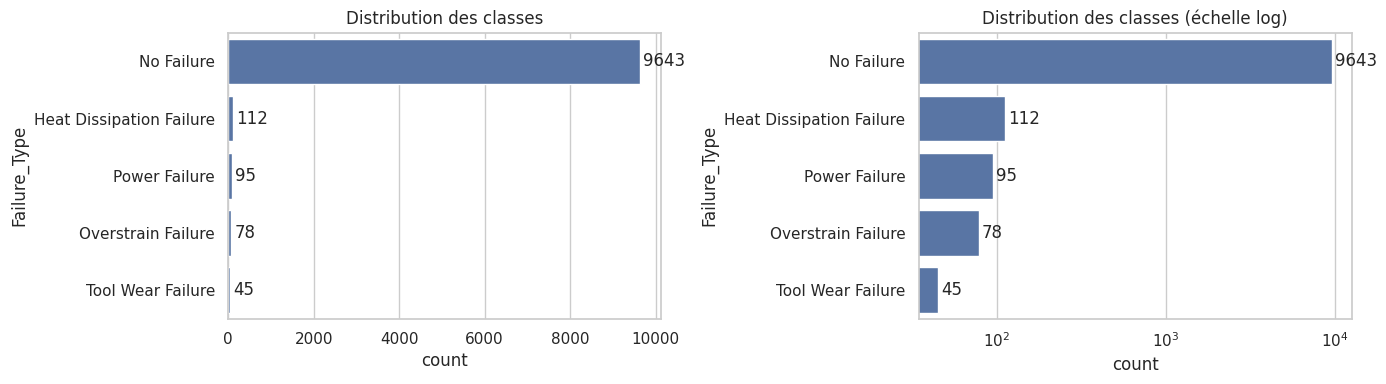

Failure_Type
No Failure                  96.69
Heat Dissipation Failure     1.12
Power Failure                0.95
Overstrain Failure           0.78
Tool Wear Failure            0.45


In [39]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
order = df["Failure_Type"].value_counts().index
sns.countplot(data=df, y="Failure_Type", order=order, ax=ax[0]); ax[0].set_title("Distribution des classes")
sns.countplot(data=df, y="Failure_Type", order=order, ax=ax[1]); ax[1].set_xscale("log"); ax[1].set_title("Distribution des classes (échelle log)")
for a in ax:
    for c in a.containers: a.bar_label(c, padding=2)
plt.tight_layout(); plt.show()
print((df["Failure_Type"].value_counts(normalize=True) * 100).round(2).to_string())

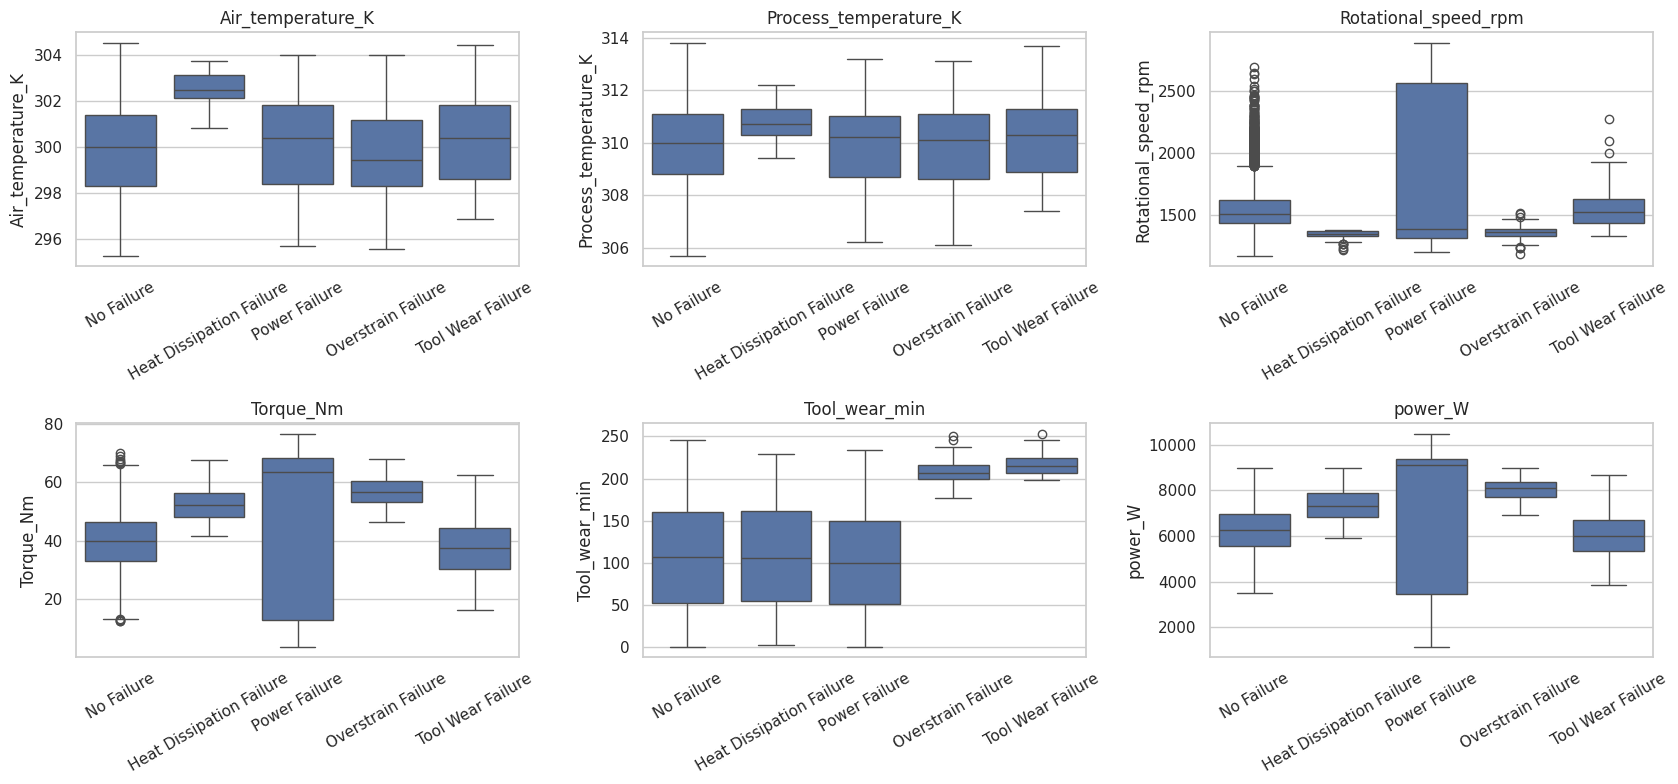

In [40]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, c in zip(axes.ravel(), num + ["power_W"]):
    sns.boxplot(data=df, x="Failure_Type", y=c, order=order, ax=ax)
    ax.set_title(c); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

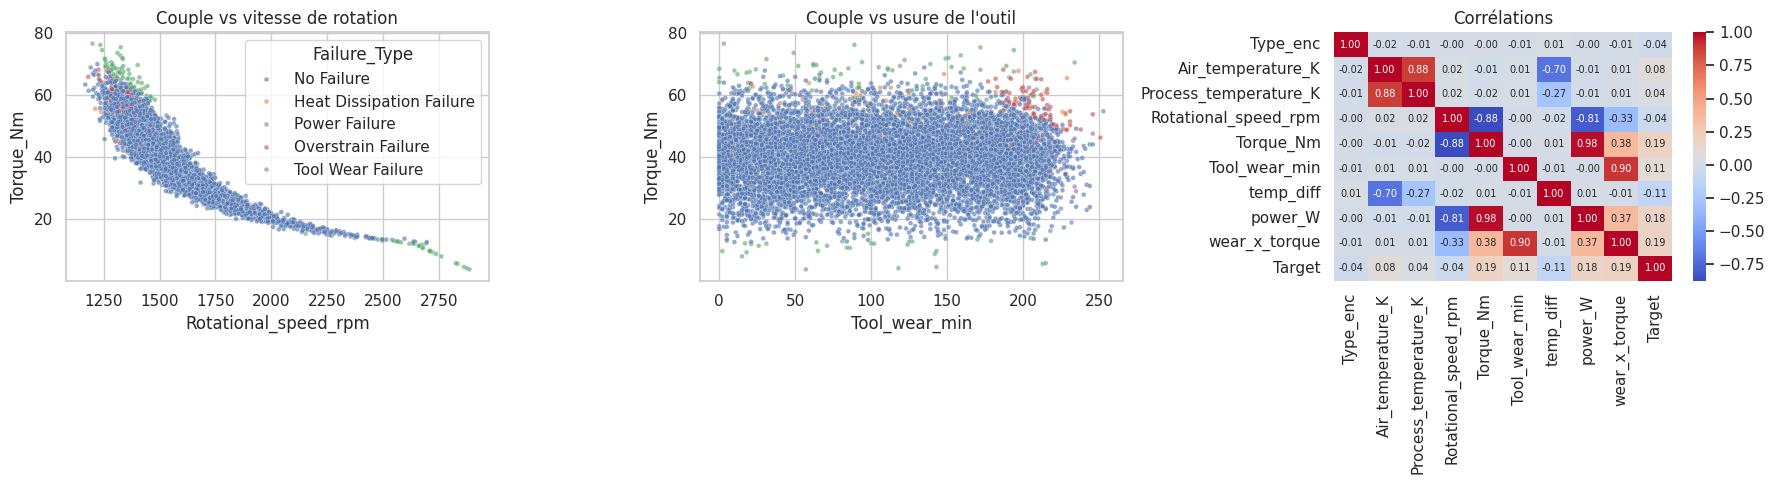

Taux de panne par qualité de produit (%) :
 Type
H    2.00
L    3.86
M    2.64


In [41]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=df, x="Rotational_speed_rpm", y="Torque_Nm", hue="Failure_Type", hue_order=order, s=12, alpha=.6, ax=ax[0])
ax[0].set_title("Couple vs vitesse de rotation")
sns.scatterplot(data=df, x="Tool_wear_min", y="Torque_Nm", hue="Failure_Type", hue_order=order, s=12, alpha=.6, ax=ax[1], legend=False)
ax[1].set_title("Couple vs usure de l'outil")
sns.heatmap(df[FEATURES + ["Target"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[2], annot_kws={"size": 7})
ax[2].set_title("Corrélations")
plt.tight_layout(); plt.show()

rate = df.groupby("Type")["Target"].mean().mul(100).round(2)
print("Taux de panne par qualité de produit (%) :\n", rate.to_string())

## 3. Découpage, standardisation et augmentation de données



train 7180 | val 798 | test 1995
Moyenne/écart-type du train après standardisation : 0.0 1.0


,avant SMOTE,après SMOTE
Heat Dissipation Failure,81,6943
No Failure,6943,6943
Overstrain Failure,56,6943
Power Failure,68,6943
Tool Wear Failure,32,6943


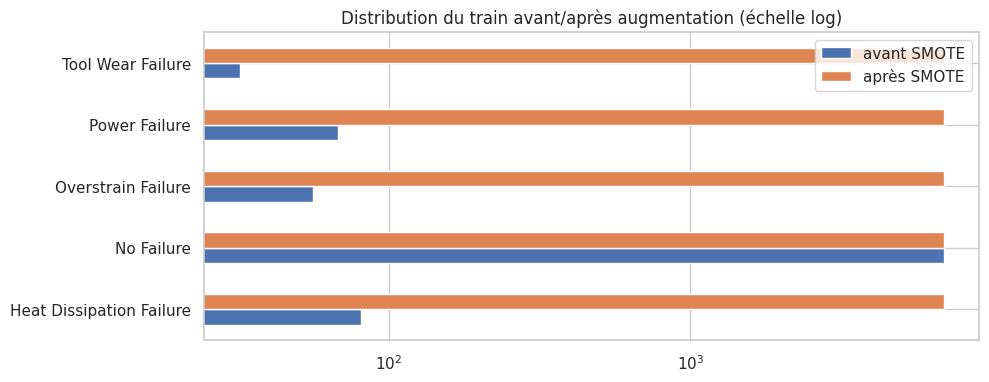

In [42]:
X_all = df[FEATURES].values.astype(np.float32)
X_trv, X_te_raw, y_trv, y_te = train_test_split(X_all, y, test_size=0.20, stratify=y, random_state=SEED)
X_tr_raw, X_va_raw, y_tr, y_va = train_test_split(X_trv, y_trv, test_size=0.10, stratify=y_trv, random_state=SEED)

scaler = StandardScaler().fit(X_tr_raw)                          # ajusté sur le train uniquement
X_tr, X_va, X_te = (scaler.transform(a).astype(np.float32) for a in (X_tr_raw, X_va_raw, X_te_raw))
print(f"train {len(X_tr)} | val {len(X_va)} | test {len(X_te)}")
print("Moyenne/écart-type du train après standardisation :", X_tr.mean().round(3), X_tr.std().round(3))

min_count = np.bincount(y_tr).min()
smote = SMOTE(k_neighbors=min(5, min_count - 1), random_state=SEED)
X_bal, y_bal = smote.fit_resample(X_tr, y_tr)
X_bal = X_bal.astype(np.float32)

cmp = pd.DataFrame({"avant SMOTE": np.bincount(y_tr), "après SMOTE": np.bincount(y_bal)}, index=CLASSES)
display(cmp)
cmp.plot.barh(figsize=(10, 4), logx=True, title="Distribution du train avant/après augmentation (échelle log)"); plt.show()

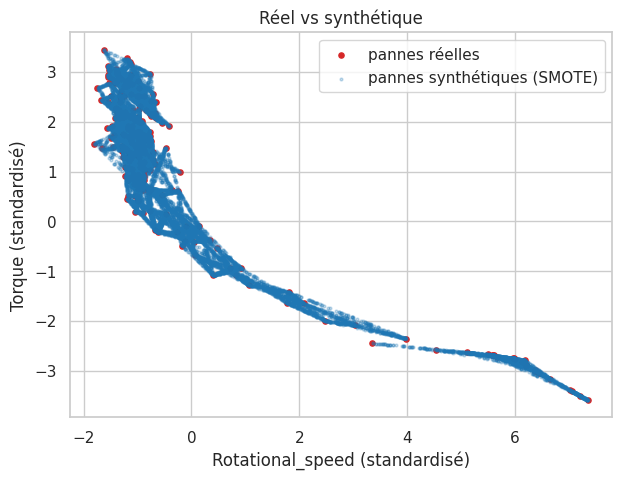

In [43]:
synth = np.arange(len(y_bal)) >= len(y_tr)
minority = y_bal != CLASSES.index("No Failure")
i_rpm, i_tq = FEATURES.index("Rotational_speed_rpm"), FEATURES.index("Torque_Nm")
plt.figure(figsize=(7, 5))
plt.scatter(X_bal[minority & ~synth, i_rpm], X_bal[minority & ~synth, i_tq], s=14, label="pannes réelles", c="tab:red")
plt.scatter(X_bal[minority & synth, i_rpm], X_bal[minority & synth, i_tq], s=4, alpha=.25, label="pannes synthétiques (SMOTE)", c="tab:blue")
plt.xlabel("Rotational_speed (standardisé)"); plt.ylabel("Torque (standardisé)"); plt.legend(); plt.title("Réel vs synthétique"); plt.show()

## 4. Architecture DNN


In [44]:
class MLP(nn.Module):
    ACT = {"relu": nn.ReLU, "tanh": nn.Tanh, "leaky_relu": nn.LeakyReLU, "gelu": nn.GELU}
    def __init__(self, in_dim, out_dim, hidden=(64, 32), activation="relu", dropout=0.0, batch_norm=False):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if batch_norm: layers.append(nn.BatchNorm1d(h))
            layers.append(self.ACT[activation]())
            if dropout > 0: layers.append(nn.Dropout(dropout))
            d = h
        layers.append(nn.Linear(d, out_dim))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

def make_optimizer(name, params, lr, weight_decay):
    name = name.lower()
    if name == "adam":    return torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    if name == "adamw":   return torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    if name == "sgd":     return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay)
    if name == "rmsprop": return torch.optim.RMSprop(params, lr=lr, weight_decay=weight_decay)
    raise ValueError(name)

class TorchMLPClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, hidden=(64, 32), activation="relu", lr=1e-3, optimizer="adam", epochs=30, batch_size=256,
                 dropout=0.0, weight_decay=0.0, batch_norm=False, label_smoothing=0.0, patience=None,
                 random_state=SEED):
        self.hidden = hidden; self.activation = activation; self.lr = lr; self.optimizer = optimizer
        self.epochs = epochs; self.batch_size = batch_size; self.dropout = dropout
        self.weight_decay = weight_decay; self.batch_norm = batch_norm; self.label_smoothing = label_smoothing
        self.patience = patience; self.random_state = random_state

    def _logits(self, X):
        self.model_.eval(); out = []
        X = torch.as_tensor(np.asarray(X, dtype=np.float32))
        with torch.no_grad():
            for i in range(0, len(X), 8192):
                out.append(self.model_(X[i:i + 8192].to(device)).cpu())
        return torch.cat(out)

    def _loss_acc(self, X, y):
        yt = torch.as_tensor(np.searchsorted(self.classes_, y), dtype=torch.long)
        lg = self._logits(X)
        return float(nn.functional.cross_entropy(lg, yt)), float((lg.argmax(1) == yt).float().mean())

    def fit(self, X, y, val_set=None, eval_sets=None):
        set_seed(self.random_state)
        X = np.asarray(X, dtype=np.float32); y = np.asarray(y)
        self.classes_ = np.unique(y); yt = np.searchsorted(self.classes_, y)
        self.model_ = MLP(X.shape[1], len(self.classes_), self.hidden, self.activation, self.dropout, self.batch_norm).to(device)
        opt = make_optimizer(self.optimizer, self.model_.parameters(), self.lr, self.weight_decay)
        loss_fn = nn.CrossEntropyLoss(label_smoothing=self.label_smoothing)
        loader = DataLoader(TensorDataset(torch.from_numpy(X), torch.from_numpy(yt).long()),
                            batch_size=self.batch_size, shuffle=True, drop_last=len(X) > self.batch_size)
        self.history_ = {}
        best_val, best_state, wait, self.best_epoch_ = np.inf, None, 0, self.epochs
        sets = dict(eval_sets or {})
        if val_set is not None: sets["val"] = val_set
        for ep in range(self.epochs):
            self.model_.train()
            for xb, yb in loader:
                xb, yb = xb.to(device), yb.to(device)
                opt.zero_grad(); loss = loss_fn(self.model_(xb), yb); loss.backward(); opt.step()
            for name, (Xe, ye) in sets.items():
                l, a = self._loss_acc(Xe, ye)
                h = self.history_.setdefault(name, {"loss": [], "acc": []}); h["loss"].append(l); h["acc"].append(a)
            if self.patience is not None and val_set is not None:
                vl = self.history_["val"]["loss"][-1]
                if vl < best_val - 1e-6:
                    best_val, best_state, wait, self.best_epoch_ = vl, copy.deepcopy(self.model_.state_dict()), 0, ep + 1
                else:
                    wait += 1
                    if wait >= self.patience: break
        if best_state is not None: self.model_.load_state_dict(best_state)
        return self

    def predict_proba(self, X): return torch.softmax(self._logits(X), dim=1).numpy()
    def predict(self, X): return self.classes_[self.predict_proba(X).argmax(1)]

print("Architecture d'exemple :\n", MLP(len(FEATURES), n_classes, (64, 32), "relu", 0.2, True))

Architecture d'exemple :
 MLP(
  (net): Sequential(
    (0): Linear(in_features=9, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=32, out_features=5, bias=True)
  )
)


## 5. Recherche des hyperparamètres avec `GridSearchCV`


In [45]:
param_grid = {
    "clf__hidden": [(32,), (64, 32), (128, 64)],
    "clf__lr": [1e-3, 1e-2],
    "clf__optimizer": ["adam", "sgd"],
    "clf__epochs": [20, 40],
}

pipe = ImbPipeline([("smote", SMOTE(k_neighbors=3, random_state=SEED)),
                    ("clf", TorchMLPClassifier(batch_size=256))])
gs = GridSearchCV(pipe, param_grid, cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                  scoring="f1_macro", n_jobs=1, refit=False, verbose=1)
gs.fit(X_tr, y_tr)

res = pd.DataFrame(gs.cv_results_).sort_values("rank_test_score")
cols = ["param_clf__hidden", "param_clf__lr", "param_clf__optimizer", "param_clf__epochs", "mean_test_score", "std_test_score", "mean_fit_time"]
display(res[cols].head(10).reset_index(drop=True))
best_params = {k.replace("clf__", ""): v for k, v in res.iloc[0]["params"].items()}
print("\nMeilleurs hyperparamètres :", best_params)

Fitting 3 folds for each of 24 candidates, totalling 72 fits


,param_clf__hidden,param_clf__lr,param_clf__optimizer,param_clf__epochs,mean_test_score,std_test_score,mean_fit_time
0,"(128, 64)",0.010,adam,20,0.686487,0.005293,4.482027
1,"(128, 64)",0.001,adam,40,0.680719,0.010413,8.848428
2,"(128, 64)",0.010,adam,40,0.678903,0.027415,8.627019
3,"(32,)",0.010,adam,40,0.671058,0.006393,6.969126
4,"(64, 32)",0.010,adam,40,0.668341,0.018295,7.920339
5,"(32,)",0.010,adam,20,0.652931,0.016029,3.607735
6,"(64, 32)",0.010,adam,20,0.647388,0.036319,4.341833
7,"(128, 64)",0.001,adam,20,0.634528,0.001362,4.436831
8,"(64, 32)",0.001,adam,40,0.630814,0.010539,7.928673
9,"(128, 64)",0.010,sgd,40,0.619696,0.015883,7.854966



Meilleurs hyperparamètres : {'epochs': 20, 'hidden': (128, 64), 'lr': 0.01, 'optimizer': 'adam'}


## 6. Modèle de base : entraînement sur les données équilibrées et courbes


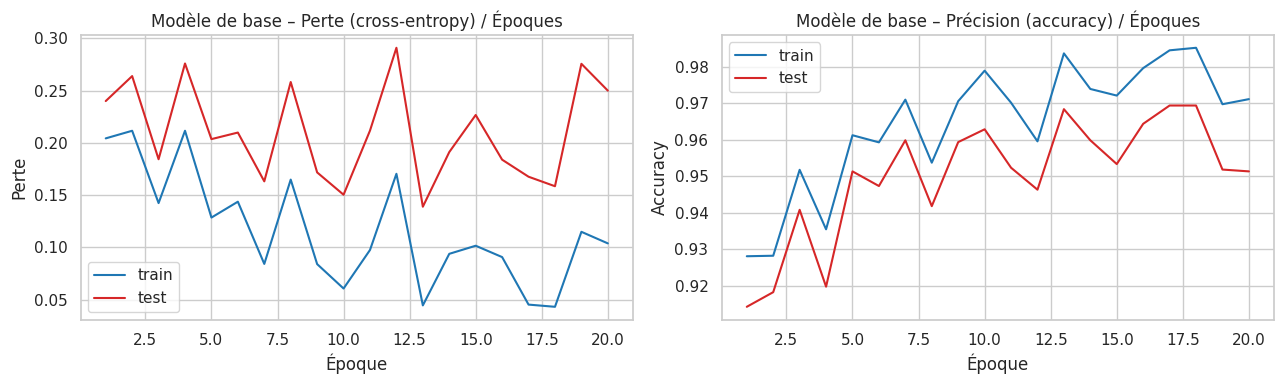

[Modèle de base] perte finale : train = 0.1038 | test = 0.2499 | écart = +0.1461
   accuracy finale : train = 97.1% | test = 95.1%
   meilleure perte test à l'époque 13/20
   → signe de SUR-APPRENTISSAGE : la perte test remonte / reste bien au-dessus du train.
   ⚠ L'accuracy est dominée par la classe « No Failure » (≈ 97 %) : juger le modèle sur le F1 macro / recall par classe.


In [46]:
EVAL = {"train": (X_tr, y_tr), "test": (X_te, y_te)}

def plot_curves(model, title):
    h = model.history_
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for k, c in (("train", "tab:blue"), ("test", "tab:red")):
        ax[0].plot(range(1, len(h[k]["loss"]) + 1), h[k]["loss"], c=c, label=k)
        ax[1].plot(range(1, len(h[k]["acc"]) + 1), h[k]["acc"], c=c, label=k)
    ax[0].set_title(f"{title} – Perte (cross-entropy) / Époques"); ax[1].set_title(f"{title} – Précision (accuracy) / Époques")
    for a, yl in zip(ax, ("Perte", "Accuracy")): a.set_xlabel("Époque"); a.set_ylabel(yl); a.legend()
    plt.tight_layout(); plt.show()

def interpret(model, name):
    h = model.history_; tl, te = np.array(h["train"]["loss"]), np.array(h["test"]["loss"])
    ta, tea = np.array(h["train"]["acc"]), np.array(h["test"]["acc"])
    msgs = [f"[{name}] perte finale : train = {tl[-1]:.4f} | test = {te[-1]:.4f} | écart = {te[-1] - tl[-1]:+.4f}",
            f"   accuracy finale : train = {ta[-1]:.1%} | test = {tea[-1]:.1%}",
            f"   meilleure perte test à l'époque {int(te.argmin()) + 1}/{len(te)}"]
    if te[-1] > 1.3 * tl[-1] and te[-1] > te.min() * 1.1:
        msgs.append("   → signe de SUR-APPRENTISSAGE : la perte test remonte / reste bien au-dessus du train.")
    elif tl[-1] > 0.5:
        msgs.append("   → perte train encore élevée : SOUS-APPRENTISSAGE possible.")
    else:
        msgs.append("   → apprentissage globalement sain (pertes train et test proches).")
    msgs.append("   ⚠ L'accuracy est dominée par la classe « No Failure » (≈ 97 %) : juger le modèle sur le F1 macro / recall par classe.")
    print("\n".join(msgs))

base = TorchMLPClassifier(batch_size=256, **best_params)
base.fit(X_bal, y_bal, eval_sets=EVAL)
plot_curves(base, "Modèle de base"); interpret(base, "Modèle de base")

## 7. Métriques sur train et test


,Accuracy,Balanced acc.,Précision (macro),Sensibilité/Recall (macro),Spécificité (macro),F1 (macro),F1 (pondéré),AUC (OvR macro)
Base – train,0.9712,0.9905,0.6447,0.9905,0.9934,0.7511,0.9766,0.9989
Base – test,0.9514,0.7446,0.5394,0.7446,0.9463,0.6043,0.9614,0.9738


Rapport de classification détaillé (TEST) :
                          precision    recall  f1-score   support

Heat Dissipation Failure      0.488     0.955     0.646        22
              No Failure      0.992     0.958     0.975      1929
      Overstrain Failure      0.611     0.688     0.647        16
           Power Failure      0.536     0.789     0.638        19
       Tool Wear Failure      0.070     0.333     0.115         9

                accuracy                          0.951      1995
               macro avg      0.539     0.745     0.604      1995
            weighted avg      0.975     0.951     0.961      1995



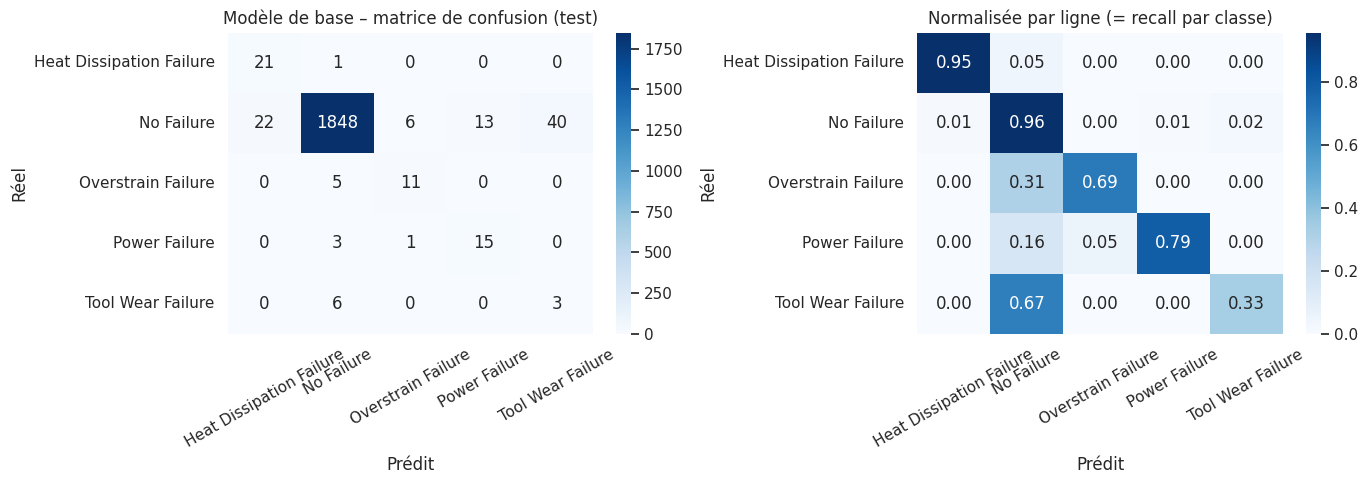

In [47]:
def full_metrics(model, X, y_true):
    pred, proba = model.predict(X), model.predict_proba(X)
    cm = confusion_matrix(y_true, pred, labels=range(n_classes))
    spec = []
    for k in range(n_classes):
        tn = cm.sum() - cm[k, :].sum() - cm[:, k].sum() + cm[k, k]; fp = cm[:, k].sum() - cm[k, k]
        spec.append(tn / (tn + fp))
    try: auc = roc_auc_score(y_true, proba, multi_class="ovr", average="macro", labels=list(range(n_classes)))
    except ValueError: auc = np.nan
    return {"Accuracy": accuracy_score(y_true, pred), "Balanced acc.": balanced_accuracy_score(y_true, pred),
            "Précision (macro)": precision_score(y_true, pred, average="macro", zero_division=0),
            "Sensibilité/Recall (macro)": recall_score(y_true, pred, average="macro", zero_division=0),
            "Spécificité (macro)": float(np.mean(spec)),
            "F1 (macro)": f1_score(y_true, pred, average="macro", zero_division=0),
            "F1 (pondéré)": f1_score(y_true, pred, average="weighted", zero_division=0), "AUC (OvR macro)": auc}

def metrics_table(model, name):
    return pd.DataFrame({f"{name} – train": full_metrics(model, X_tr, y_tr), f"{name} – test": full_metrics(model, X_te, y_te)}).T

display(metrics_table(base, "Base").round(4))
print("Rapport de classification détaillé (TEST) :")
print(classification_report(y_te, base.predict(X_te), target_names=CLASSES, zero_division=0, digits=3))

def plot_cm(model, title):
    cm = confusion_matrix(y_te, model.predict(X_te), labels=range(n_classes))
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0]); ax[0].set_title(f"{title} – matrice de confusion (test)")
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1]); ax[1].set_title("Normalisée par ligne (= recall par classe)")
    for a in ax: a.set_xlabel("Prédit"); a.set_ylabel("Réel"); a.tick_params(axis="x", rotation=30)
    plt.tight_layout(); plt.show()
plot_cm(base, "Modèle de base")

## 8. Régularisation et comparaison


In [48]:
longer = max(int(best_params["epochs"]) * 2, 80)
experiments = {
    "L2 (weight decay)": dict(weight_decay=1e-3),
    "Dropout (0.3)": dict(dropout=0.3),
    "BatchNorm": dict(batch_norm=True),
    "Label smoothing": dict(label_smoothing=0.1),
    "Early stopping": dict(epochs=longer, patience=8),
    "Combiné": dict(dropout=0.3, weight_decay=1e-4, batch_norm=True, label_smoothing=0.1, epochs=longer, patience=8),
}
models = {"Modèle de base": base}
for name, extra in experiments.items():
    m = TorchMLPClassifier(batch_size=256, **{**best_params, **extra})
    m.fit(X_bal, y_bal, val_set=(X_va, y_va), eval_sets=EVAL)
    models[name] = m
    print(f"{name:<18} entraîné ({len(m.history_['train']['loss'])} époques, meilleure époque = {m.best_epoch_})")

rows = []
for name, m in models.items():
    tr, te = full_metrics(m, X_tr, y_tr), full_metrics(m, X_te, y_te)
    rows.append({"Modèle": name, "Acc train": tr["Accuracy"], "Acc test": te["Accuracy"],
                 "Recall macro train": tr["Sensibilité/Recall (macro)"], "Recall macro test": te["Sensibilité/Recall (macro)"],
                 "F1 macro train": tr["F1 (macro)"], "F1 macro test": te["F1 (macro)"],
                 "F1 pondéré test": te["F1 (pondéré)"], "AUC test": te["AUC (OvR macro)"]})
table = pd.DataFrame(rows).set_index("Modèle")
table["Δ F1 (train−test)"] = table["F1 macro train"] - table["F1 macro test"]
display(table.round(4))

L2 (weight decay)  entraîné (20 époques, meilleure époque = 20)
Dropout (0.3)      entraîné (20 époques, meilleure époque = 20)
BatchNorm          entraîné (20 époques, meilleure époque = 20)
Label smoothing    entraîné (20 époques, meilleure époque = 20)
Early stopping     entraîné (21 époques, meilleure époque = 13)
Combiné            entraîné (25 époques, meilleure époque = 17)


,Acc train,Acc test,Recall macro train,Recall macro test,F1 macro train,F1 macro test,F1 pondéré test,AUC test,Δ F1 (train−test)
Modèle,,,,,,,,,
Modèle de base,0.9712,0.9514,0.9905,0.7446,0.7511,0.6043,0.9614,0.9738,0.1468
L2 (weight decay),0.9370,0.9258,0.9810,0.8753,0.6242,0.5920,0.9470,0.9847,0.0323
Dropout (0.3),0.9409,0.9308,0.9818,0.8399,0.6377,0.5941,0.9502,0.9770,0.0436
BatchNorm,0.9777,0.9574,0.9954,0.7623,0.8118,0.6583,0.9675,0.9710,0.1535
Label smoothing,0.9830,0.9644,0.9965,0.7354,0.8264,0.6382,0.9703,0.9692,0.1882
Early stopping,0.9837,0.9684,0.9904,0.7585,0.8236,0.6578,0.9723,0.9767,0.1658
Combiné,0.9235,0.9113,0.9813,0.8944,0.6240,0.5867,0.9391,0.9855,0.0373


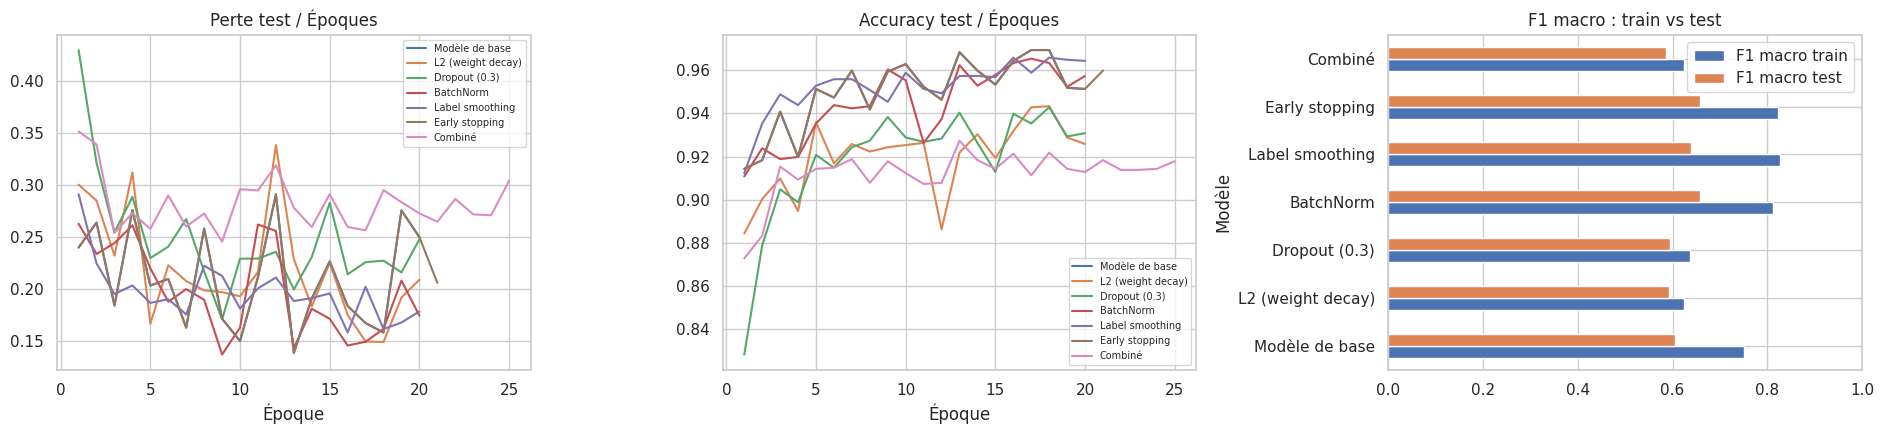

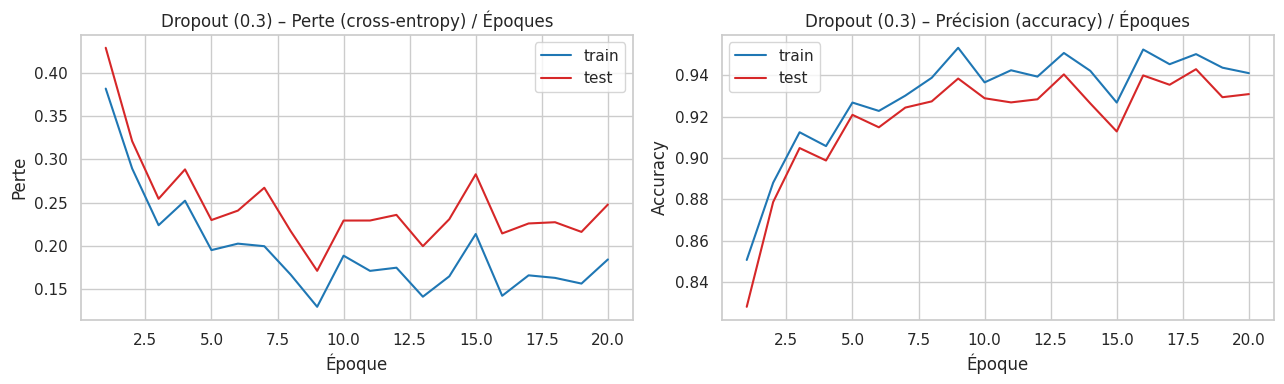

[Dropout (0.3)] perte finale : train = 0.1843 | test = 0.2478 | écart = +0.0636
   accuracy finale : train = 94.1% | test = 93.1%
   meilleure perte test à l'époque 9/20
   → signe de SUR-APPRENTISSAGE : la perte test remonte / reste bien au-dessus du train.
   ⚠ L'accuracy est dominée par la classe « No Failure » (≈ 97 %) : juger le modèle sur le F1 macro / recall par classe.


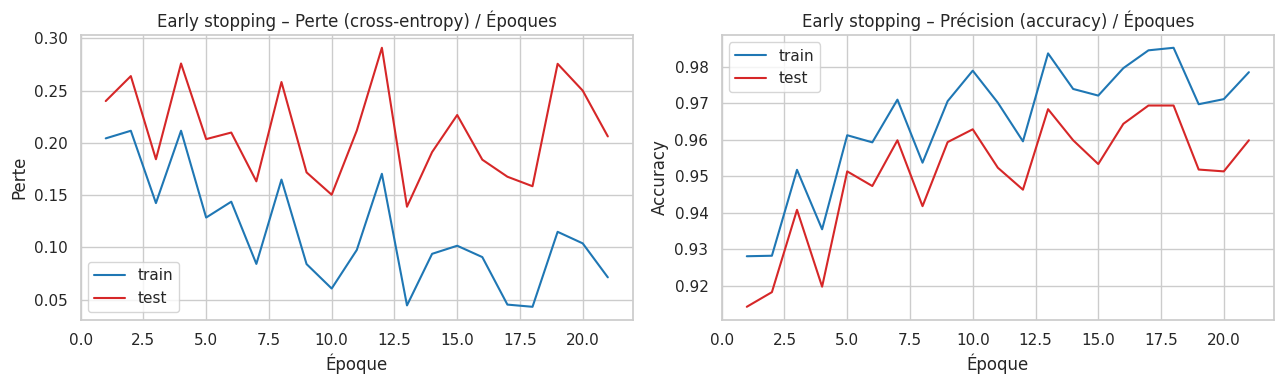

[Early stopping] perte finale : train = 0.0713 | test = 0.2061 | écart = +0.1348
   accuracy finale : train = 97.9% | test = 96.0%
   meilleure perte test à l'époque 13/21
   → signe de SUR-APPRENTISSAGE : la perte test remonte / reste bien au-dessus du train.
   ⚠ L'accuracy est dominée par la classe « No Failure » (≈ 97 %) : juger le modèle sur le F1 macro / recall par classe.


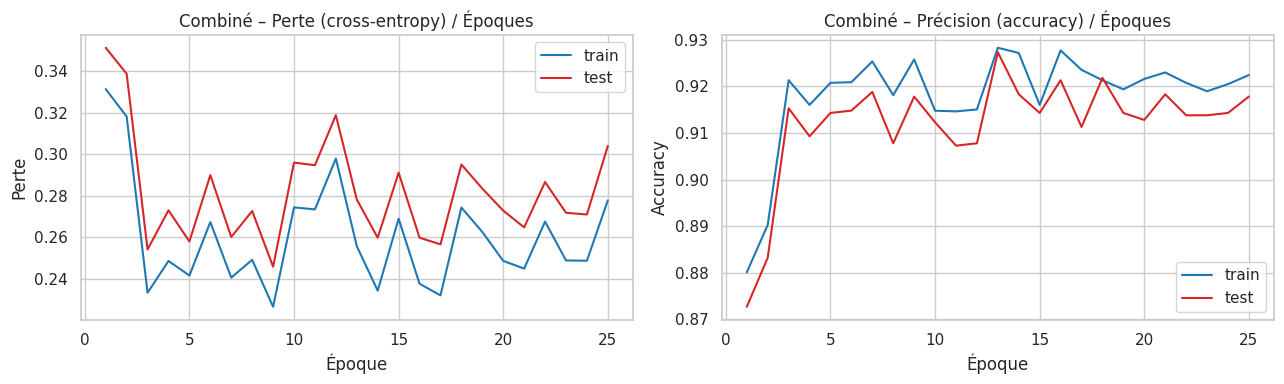

[Combiné] perte finale : train = 0.2777 | test = 0.3039 | écart = +0.0262
   accuracy finale : train = 92.2% | test = 91.8%
   meilleure perte test à l'époque 9/25
   → apprentissage globalement sain (pertes train et test proches).
   ⚠ L'accuracy est dominée par la classe « No Failure » (≈ 97 %) : juger le modèle sur le F1 macro / recall par classe.


In [49]:
fig, ax = plt.subplots(1, 3, figsize=(19, 4.5))
for name, m in models.items():
    ax[0].plot(range(1, len(m.history_["test"]["loss"]) + 1), m.history_["test"]["loss"], label=name)
    ax[1].plot(range(1, len(m.history_["test"]["acc"]) + 1), m.history_["test"]["acc"], label=name)
ax[0].set_title("Perte test / Époques"); ax[1].set_title("Accuracy test / Époques")
for a in ax[:2]: a.set_xlabel("Époque"); a.legend(fontsize=7)
table[["F1 macro train", "F1 macro test"]].plot.barh(ax=ax[2]); ax[2].set_title("F1 macro : train vs test"); ax[2].set_xlim(0, 1)
plt.tight_layout(); plt.show()

for name in ["Dropout (0.3)", "Early stopping", "Combiné"]:
    plot_curves(models[name], name); interpret(models[name], name)

Meilleur modèle selon le F1 macro test : BatchNorm


,Accuracy,Balanced acc.,Précision (macro),Sensibilité/Recall (macro),Spécificité (macro),F1 (macro),F1 (pondéré),AUC (OvR macro)
BatchNorm – train,0.9777,0.9954,0.7414,0.9954,0.9955,0.8118,0.9832,0.9997
BatchNorm – test,0.9574,0.7623,0.5993,0.7623,0.9563,0.6583,0.9675,0.9710


                          precision    recall  f1-score   support

Heat Dissipation Failure      0.690     0.909     0.784        22
              No Failure      0.994     0.963     0.978      1929
      Overstrain Failure      0.700     0.875     0.778        16
           Power Failure      0.571     0.842     0.681        19
       Tool Wear Failure      0.042     0.222     0.070         9

                accuracy                          0.957      1995
               macro avg      0.599     0.762     0.658      1995
            weighted avg      0.980     0.957     0.967      1995



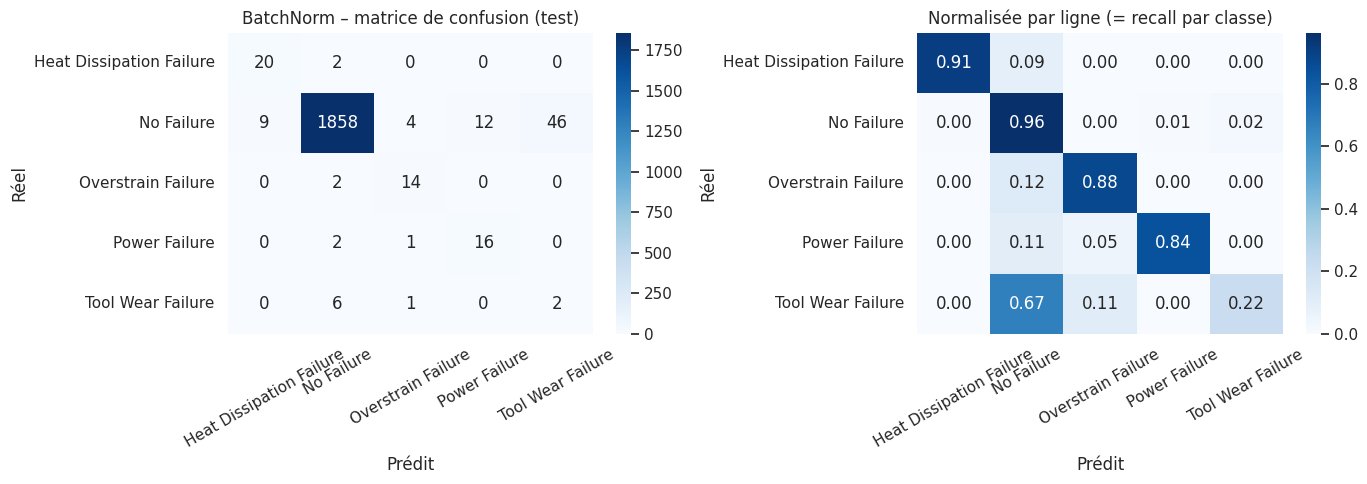


Meilleurs hyperparamètres : {'epochs': 20, 'hidden': (128, 64), 'lr': 0.01, 'optimizer': 'adam'}


In [50]:
best_name = table["F1 macro test"].idxmax(); best_model = models[best_name]
print("Meilleur modèle selon le F1 macro test :", best_name)
display(metrics_table(best_model, best_name).round(4))
print(classification_report(y_te, best_model.predict(X_te), target_names=CLASSES, zero_division=0, digits=3))
plot_cm(best_model, best_name)

os.makedirs("results", exist_ok=True)
table.round(4).to_csv("results/part2_classification_results.csv")
print("\nMeilleurs hyperparamètres :", best_params)